# 06 — La función de decisión

**La pregunta rectora:**

> Dado un presupuesto de USD 80.000 a 200.000 y un horizonte de 5 años, ¿qué propiedad
> ofrece la mejor combinación de retorno esperado, liquidez y riesgo, y supera esa
> combinación la de no comprar y quedarse en renta fija en dólares?

Se descompone en tres decisiones, cada una con un criterio declarado antes de mirar los
resultados:

| Decisión | Criterio |
|---|---|
| **P1** — ¿comprar o no comprar? | Recomendar la propiedad solo si su rentabilidad neta, calculada sobre el **extremo inferior** de su banda, supera la **TIR de las obligaciones negociables en dólares al mismo plazo** (la vara), más un margen por liquidez |
| **P2** — ¿qué propiedad? | Recomendar A sobre B solo si sus bandas **no se superponen** |
| **P3** — ¿tradicional o temporal? | Neta contra neta: el temporal conviene solo si la ocupación que se puede sostener supera la **ocupación de equilibrio** de la celda |

**Implementar es la mitad. La otra mitad es evaluar:** cuántas propiedades pasan P1, en
qué proporción de los pares la banda permite distinguir, en cuántas celdas gana el
temporal, y cómo cambia todo eso si se mueven los supuestos.

El cálculo está en `src/decision.py`, que agrega las columnas de la decisión al dataset
analítico (son las que usa el tablero), y `src/test_decision.py` lo verifica contra la
comparación de todos los pares uno por uno y contra `kpis.py` y `temporal.py`.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import decision as D
import eda
import supuestos as S

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

P = "../data/processed"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
for c in ["en_presupuesto", "en_soporte_modelo", "precio_es_total", "excluida_revision", "universo_decision",
          "p1_comprar", "p1_comprar_con_entrada", "p2_no_dominada"]:
    df[c] = df[c].fillna(False).astype(bool)
sens = pd.read_csv(f"{P}/decision_sensibilidad.csv", encoding="utf-8-sig")
p3 = pd.read_csv(f"{P}/decision_p3.csv", encoding="utf-8-sig")
temporal = pd.read_csv(f"{P}/temporal_vs_tradicional.csv", encoding="utf-8-sig")
revision = pd.read_csv("../data/reference/revision_listas.csv", encoding="utf-8-sig")
curva = pd.read_csv(f"{P}/curva_on.csv", encoding="utf-8-sig")
vara = S.RETORNO_MIN_PCT + S.MARGEN_LIQUIDEZ_PCT
print(f"Vara de P1: {vara:.2f}% (TIR de las ON a {S.HORIZONTE_ANIOS} anios; banda p25 a p75: "
      f"{S.RETORNO_MIN_PISO_PCT:.2f}% a {S.RETORNO_MIN_TECHO_PCT:.2f}%). Precios del {S.CURVA_ON_FECHA}")

Vara de P1: 6.26% (TIR de las ON a 5 anios; banda p25 a p75: 6.13% a 6.53%). Precios del 2026-11-13



## 0. La vara: renta fija en dólares al plazo del inversor

El inmueble se evalúa a 5 años, así que la alternativa tiene que ser del mismo plazo: un
bono a 11 años paga más que uno a 5 por el plazo, no por ser mejor alternativa.
`src/curva_on.py` arma una **curva** con 31 obligaciones negociables bullet en dólares de
emisores de primera línea (YPF, Pampa, Pan American, Pluspetrol, TGS y Telecom). Los
términos de cada bono (cupón, vencimiento, amortización) son del reporte de ON de
Criteria del 2do trimestre de 2026, y los precios, de la API pública de data912.com, que
publica los de BYMA. La TIR la calcula el código con la misma convención que la TIR del
inmueble (efectiva anual), y la consulta queda guardada con su fecha en
`data/external/on_precios.csv`, así que el resultado se reproduce sin red.

La vara de P1 es la **mediana de las ON que vencen a 5 años ± 1**, y la banda que se usa
en la sensibilidad va de su p25 a su p75.


In [2]:

tabla_curva = pd.DataFrame([S.retorno_minimo(h) for h in (1, 2, 3, 5)]).set_index("plazo")
tabla_curva.columns = ["ON en la ventana", "TIR mediana (%)", "p25 (%)", "p75 (%)"]
display(tabla_curva)
print(f"ON con precio: {len(curva)}. Si el precio de la API incluyera el cupon corrido, la vara a "
      f"{S.HORIZONTE_ANIOS} anios seria {curva.loc[curva['plazo_anios'].between(S.HORIZONTE_ANIOS - 1, S.HORIZONTE_ANIOS + 1), 'tir_si_precio_sucio_pct'].median():.2f}%")


,ON en la ventana,TIR mediana (%),p25 (%),p75 (%)
plazo,,,,
1,8,3.57,2.98,4.24
2,11,4.34,3.93,4.97
3,8,5.23,4.98,5.50
5,5,6.26,6.13,6.53


ON con precio: 26. Si el precio de la API incluyera el cupon corrido, la vara a 5 anios seria 6.76%



**Lectura.** La curva sube con el plazo, como se espera: comparar el inmueble a 5 años
contra un bono a 11 exigía de más. La convención de precio (limpio o con el cupón
corrido) mueve la vara medio punto; `curva_on.py` explica por qué se toma el precio como
limpio (el residuo contra la TIR de Criteria no crece con el cupón corrido).


## 1. El universo de la decisión

Entran las ventas con estimación confiable y dentro del presupuesto, con tres filtros más:

- **El soporte del modelo.** Una propiedad entra solo si su celda tipo × tramo de
  superficie tiene al menos 30 alquileres observados (`supuestos.MIN_ALQ_SOPORTE`). La
  razón se ve abajo: sin el filtro, las primeras de la lista son casas de 6 a 10
  ambientes.
- **El precio publicado tiene que ser el total.** Quedan afuera las ventas con
  financiación del vendedor o en pozo (`financiacion` y `en_pozo`, de la minería de
  texto): el precio suele ser solo la parte al contado ("USD 91.000 más 13 cuotas de
  USD 3.500"), y una unidad en pozo no se alquila hasta la entrega.
- **La revisión a mano.** Los primeros puestos de P1 y P2 se leyeron aviso por aviso.
  Los que no corresponden (oficinas, usos mixtos) se excluyen con su motivo en
  `data/reference/revision_listas.csv`; los que tienen algo para verificar llevan una
  alerta.

In [3]:
v = df[df["operacion"] == "venta"]
conf = v[v["estimacion_confiable"] == 1]
pres = conf[conf["en_presupuesto"]]
sop = pres[pres["en_soporte_modelo"]]
tot = sop[sop["precio_es_total"]]
u = df[df["universo_decision"]].copy()
embudo = pd.DataFrame({"propiedades": [len(v), len(conf), len(pres), len(sop), len(tot), len(u)]},
                      index=["ventas", "con estimacion confiable", "dentro del presupuesto",
                             "en el soporte del modelo", "con precio total (sin financiacion ni pozo)",
                             "sin exclusion de la revision (universo)"])
display(embudo)
alq = df[df["operacion"] == "alquiler"]
display(pd.crosstab(alq["tipo_familia"], alq["superficie_rango"])
        .reindex(columns=S.ORDEN_SUPERFICIE_RANGO).rename_axis(index="alquileres observados"))

,propiedades
ventas,10749
con estimacion confiable,9203
dentro del presupuesto,5198
en el soporte del modelo,4484
con precio total (sin financiacion ni pozo),3774
sin exclusion de la revision (universo),3766


superficie_rango,hasta 35,36-55,56-80,81-120,120+
alquileres observados,,,,,
casa,0,0,1,1,12
departamento,314,587,232,109,48
ph,3,12,10,11,8


In [4]:
# Las cinco de mayor neta central dentro del presupuesto, SIN el filtro de soporte.
cols = ["barrio", "tipo_familia", "ambientes", "sup_total_m2", "venta_usd", "alquiler_est_usd_mes",
        "rent_neta_pct", "n_alq_celda_tipo"]
pres.sort_values("rent_neta_pct", ascending=False)[cols].head(5)

,barrio,tipo_familia,ambientes,sup_total_m2,venta_usd,alquiler_est_usd_mes,rent_neta_pct,n_alq_celda_tipo
2048,villa luro,casa,9.00,320.00,"190,000.00","5,232.33",27.40,12.00
9302,monserrat,ph,10.00,124.74,"105,000.00","2,421.06",23.04,8.00
5719,barracas,casa,8.00,230.30,"179,900.00","3,670.68",20.47,12.00
9556,flores,casa,6.00,233.00,"129,000.00","2,475.33",19.04,12.00
5522,parque chacabuco,casa,5.00,182.00,"112,000.00","2,113.72",18.79,12.00


**Lectura.** Hay 14 alquileres observados de casas y 44 de PH, contra 1.290 de
departamentos. Sin el filtro, la propiedad de mayor rentabilidad es una casa de 9
ambientes en Villa Luro (en realidad, "2 PH en block") a la que el modelo le estima
USD 5.000 de alquiler por mes. No es una oportunidad: es el modelo extrapolando donde
no tiene datos. **Las casas y los PH quedan fuera de las recomendaciones**: el trabajo no
tiene con qué compararlos entre sí ni contra un departamento. Siguen en el dataset, con
la columna `en_soporte_modelo` en falso.


### La revisión a mano

Cómo se hizo: se leyeron título y descripción de las que pasan P1 con costos de entrada y
de los primeros puestos de P2 en el orden del tablero, y se buscaron en el resto de las
listas las señales de riesgo (oficina, local, consultorio, con renta, cuotas, entrega,
refacción). Criterio: se **excluye** lo que se ofrece como oficina o hoy tiene un uso
mixto; "apto profesional" solo no excluye, porque es un permiso habitual en una vivienda.
Se **alerta**, sin excluir, lo que hay que verificar antes de decidir. Una alerta
automática marca además los avisos cuya superficie cubierta es menos del 70% de la total
(terrazas y patios inflan el alquiler estimado).


In [5]:

print(revision["accion"].value_counts().to_string())
excl = revision[revision["accion"] == "excluir"].merge(df[["id_aviso", "barrio", "sup_total_m2", "venta_usd", "titulo"]],
                                                       on="id_aviso")
with pd.option_context("display.max_colwidth", 70):
    display(excl[["barrio", "sup_total_m2", "venta_usd", "titulo", "motivo"]])
print(f"Alertas en el universo: {int(u['alerta_revision'].notna().sum())}; entre las que pasan P1: "
      f"{int(u.loc[u['p1_comprar'], 'alerta_revision'].notna().sum())} de {int(u['p1_comprar'].sum())}")


accion
alertar    21
excluir     8


,barrio,sup_total_m2,venta_usd,titulo,motivo
0,parque chacabuco,178.00,"130,000.00",DEPTO 7 AMBIENTES EN VENTA PARQUE CHACABUCO,Uso mixto: el piso está dividido en vivienda y sector profesional.
1,san nicolas,140.00,"110,000.00",Piso en venta 7 ambientes - Oportunidad,"Se ofrece como departamento u oficina en el microcentro, con kitch..."
2,recoleta,91.68,"142,000.00",VENTA DEPARTAMENTO 6 AMBIENTES RECOLETA BAULERA,Actualmente se usa como oficina.
3,san nicolas,109.00,"114,900.00",Oficina en venta cocina fichero y 2 despachos,"Es una oficina: cocina, fichero y despachos."
4,san nicolas,113.60,"135,000.00",OFICINA 113m² DIVISIBLE VENTA FLIPPING AirBnb,Es una oficina divisible.
5,san nicolas,71.00,"95,000.00",VENTA DEPARTAMENTO 3 AMBIENTES Y COCHERA CONGRESO,Hoy es un consultorio odontológico y se vende con renta.
6,almagro,76.75,"85,000.00",VENTA DEPARTAMENTO 3 AMB + PATIO + PARRI ALMAGRO,Uso mixto: incluye un local comercial a la calle.
7,san nicolas,107.70,"150,000.00",Venta Oficina 5 amb San Nicolás frente al T Colón,Se ofrece como oficina: departamento convertido en estudio.


Alertas en el universo: 300; entre las que pasan P1: 15 de 93


## 2. P1 — ¿Comprar o no comprar?

**Método.** Para cada propiedad, la neta del **escenario pesimista**: el alquiler del
percentil 10 de su banda, con la misma vacancia y los mismos gastos que el KPI 2. El ABL
en pesos es el mismo, así que sobre un alquiler más bajo pesa más. Se recomienda comprar
si esa neta supera la vara. El margen por liquidez no tiene fuente: en el caso base es 0,
lo más favorable a comprar.

Como versión estricta se usa la **TIR pesimista a 5 años**, que suma los costos de
entrada y la refacción. Es la cifra que se compara de verdad con una ON del mismo plazo.
Para las unidades a reciclar, el alquiler refaccionado sube según un supuesto explícito
(`supuestos.SUBA_REFACCION`): el modelo tiene un coeficiente de `a_reciclar`, pero sale
de muy pocos alquileres, y la sensibilidad prueba sin suba y con el efecto completo.

In [6]:
p1 = pd.DataFrame({
    "pasan": [int(u["p1_comprar"].sum()), int(u["p1_comprar_con_entrada"].sum())],
    "% del universo": [u["p1_comprar"].mean() * 100, u["p1_comprar_con_entrada"].mean() * 100],
}, index=["neta pesimista > vara", f"TIR pesimista a {S.HORIZONTE_ANIOS} anios > vara (con costos de entrada)"])
display(p1)
print(f"Neta del universo: pesimista mediana {u['neta_min_pct'].median():.2f}%, central mediana "
      f"{u['rent_neta_pct'].median():.2f}%, optimista mediana {u['neta_max_pct'].median():.2f}%")
print(f"La neta pesimista mediana queda {vara - u['neta_min_pct'].median():.2f} pp debajo de la vara")
print(f"Propiedades cuya neta CENTRAL supera la vara: {int((u['rent_neta_pct'] > vara).sum())} "
      f"({(u['rent_neta_pct'] > vara).mean():.1%})")

,pasan,% del universo
neta pesimista > vara,93,2.47
TIR pesimista a 5 anios > vara (con costos de entrada),12,0.32


Neta del universo: pesimista mediana 4.13%, central mediana 5.41%, optimista mediana 6.81%
La neta pesimista mediana queda 2.13 pp debajo de la vara
Propiedades cuya neta CENTRAL supera la vara: 861 (22.9%)


### Gráfico 13 — ¿Cuántas propiedades le ganan a una ON aun en el escenario pesimista?

Distribución de la rentabilidad neta pesimista (alquiler del percentil 10) de las
propiedades del universo, contra la vara: la TIR de las ON en dólares a 5 años.

guardado: ../graficos\13_p1_neta_pesimista.png


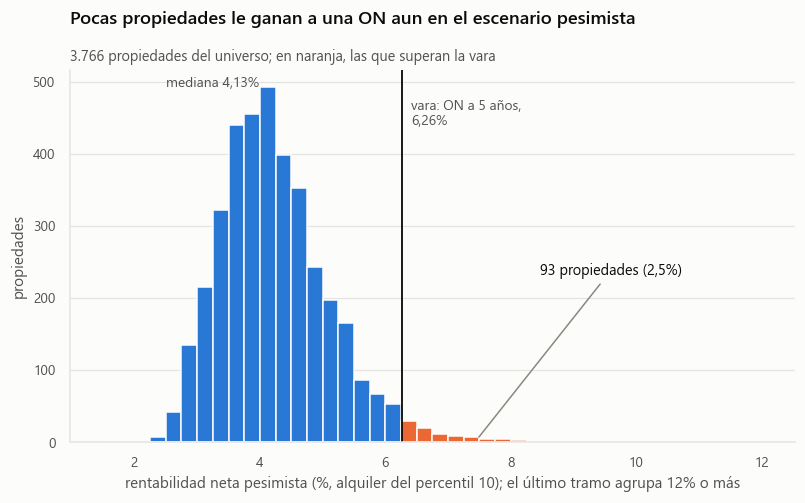

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = u["neta_min_pct"].clip(upper=12)
bordes = np.arange(1.5, 12.25, 0.25)
ax.hist(x[x <= vara], bins=bordes, color=eda.SERIE_1, edgecolor=eda.SUPERFICIE, linewidth=1)
ax.hist(x[x > vara], bins=bordes, color=eda.SERIE_2, edgecolor=eda.SUPERFICIE, linewidth=1)
ax.axvline(vara, color=eda.TINTA, linewidth=1.2)
ax.annotate(f"vara: ON a {S.HORIZONTE_ANIOS} años,\n{vara:.2f}%".replace(".", ","), (vara, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=eda.TINTA_2, va="top")
n_p1 = int(u["p1_comprar"].sum())
ax.annotate(f"{n_p1} propiedades ({n_p1 / len(u):.1%})".replace(".", ","), (vara + 1.2, 4), xytext=(vara + 2.2, ax.get_ylim()[1] * 0.45),
            fontsize=9.5, color=eda.TINTA, ha="left",
            arrowprops={"arrowstyle": "-", "color": eda.TINTA_3, "linewidth": 1})
ax.annotate(f"mediana {u['neta_min_pct'].median():.2f}%".replace(".", ","),
            (u["neta_min_pct"].median(), ax.get_ylim()[1] * 0.98),
            xytext=(-6, 0), textcoords="offset points", fontsize=9, color=eda.TINTA_2, ha="right", va="top")
ax.set_xlabel("rentabilidad neta pesimista (%, alquiler del percentil 10); el último tramo agrupa 12% o más")
ax.set_ylabel("propiedades")
ax.grid(False, axis="x")
eda.titulo(ax, "Pocas propiedades le ganan a una ON aun en el escenario pesimista",
           f"{len(u):,} propiedades del universo".replace(",", ".") + "; en naranja, las que superan la vara")
eda.guardar(fig, 13, "p1_neta_pesimista")
plt.show()

In [8]:
# Las que pasan: que tienen en comun.
cols = ["barrio", "superficie_rango", "ambientes", "venta_usd", "rent_neta_pct", "neta_min_pct", "neta_max_pct",
        "tir_5a_min_pct", "m2_relativo_celda", "a_reciclar", "p1_comprar_con_entrada", "titulo"]
pasan = u[u["p1_comprar"]].sort_values("neta_min_pct", ascending=False)
print(f"Precio del m2 contra el mediano de su celda barrio x tramo: mediana {pasan['m2_relativo_celda'].median():.2f} "
      f"(el universo: {u['m2_relativo_celda'].median():.2f})")
with pd.option_context("display.max_colwidth", 45):
    display(pasan[cols])

Precio del m2 contra el mediano de su celda barrio x tramo: mediana 0.78 (el universo: 1.00)


,barrio,superficie_rango,ambientes,venta_usd,rent_neta_pct,neta_min_pct,neta_max_pct,tir_5a_min_pct,m2_relativo_celda,a_reciclar,p1_comprar_con_entrada,titulo
8377,balvanera,120+,7.00,"148,000.00",11.77,9.18,14.36,7.80,0.96,0,True,Venta departamento 6 ambientes tipo PH Fr...
6091,monserrat,120+,5.00,"95,000.00",12.54,8.84,19.95,4.62,0.43,1,False,departamento 5 ambientes a refaccionar / ...
6206,balvanera,81-120,5.00,"115,000.00",11.07,8.64,14.08,7.28,0.77,0,True,VENTA DPTO 5AMB BALVANERA APTO PROFESIONAL
7955,constitucion,120+,4.00,"109,900.00",11.14,8.27,16.32,6.92,0.71,0,True,Departamento 4 Amb. al Frente en Constitu...
2145,san cristobal,81-120,4.00,"96,500.00",10.22,8.24,13.25,6.89,0.85,0,True,4 amb vista abierta en San Cristobal
...,...,...,...,...,...,...,...,...,...,...,...,...
5353,balvanera,56-80,3.00,"83,000.00",8.09,6.30,10.39,5.02,0.81,0,False,VENTA DEPARTAMENTO TRES AMBIENTES EN BALV...
8239,san nicolas,120+,5.00,"157,000.00",9.50,6.29,13.23,4.91,0.77,0,False,VENTA DEPARTAMENTO 5 AMBIENTES CON BALCON...
7857,monserrat,81-120,4.00,"105,000.00",8.88,6.28,12.69,5.00,0.78,0,False,Venta Departamento Montserrat 4 Ambientes
9761,balvanera,81-120,3.00,"89,000.00",7.60,6.27,10.75,2.30,0.69,1,False,VENTA 3 AMB A REFACCIONAR PATIO 97 MTS -ONCE


**Lectura.**

- **Para la propiedad típica, la respuesta a P1 es no comprar.** La neta pesimista
  mediana queda debajo de la vara (la distancia se imprime arriba), y la neta central
  de la mayoría también: es el hallazgo central del trabajo, ahora como decisión.
- **Pasan pocas, y muchas menos con costos de entrada.** Con la TIR a 5 años, que es la
  comparación honesta con una ON, el filtro deja un puñado de propiedades.
- **Las que pasan tienen algo en común: son baratas para su celda.** Cuestan menos por m²
  que la mediana de su barrio y tramo (la mediana del cociente se imprime arriba). Puede
  ser una oportunidad o algo que el aviso no dice (estado, uso, ubicación). Por eso se
  leyeron a mano, y **la función de decisión las señala para verificar, no para comprar
  a ciegas.** Es la columna `m2_relativo_celda` del tablero, junto con la alerta de la
  revisión.

## 3. P2 — ¿Qué propiedad?

**Método.** A se recomienda sobre B solo si la neta pesimista de A supera la optimista
de B. Se mide en qué proporción de los pares eso ocurre, y cuáles propiedades **no están
dominadas** por ninguna otra (la frontera). Dentro de la frontera, ninguna se distingue
de otra por rentabilidad: la elección se decide por liquidez o por riesgo.

In [9]:
lo, hi = u["neta_min_pct"], u["neta_max_pct"]
pares = pd.DataFrame({"pares con bandas que no se superponen (%)": [
    D.pares_distinguibles(lo, hi) * 100,
    D.pares_distinguibles_por_grupo(lo, hi, u["superficie_rango"]) * 100,
    D.pares_distinguibles_por_grupo(lo, hi, u["barrio"]) * 100]},
    index=["todos los pares", "mismo tramo de superficie", "mismo barrio"])
display(pares)
front = u[u["p2_no_dominada"]]
print(f"Frontera: {len(front)} de {len(u):,} propiedades ({len(front) / len(u):.1%}). "
      f"Ancho mediano de la banda de neta: {(hi - lo).median():.2f} pp")
mejor = u["rent_neta_pct"].idxmax()
print(f"La de mayor neta central ({u.loc[mejor, 'rent_neta_pct']:.2f}%) supera con claridad al "
      f"{(hi < u.loc[mejor, 'neta_min_pct']).mean():.1%} del universo, pero no a las otras "
      f"{len(front) - 1} de la frontera")

,pares con bandas que no se superponen (%)
todos los pares,7.19
mismo tramo de superficie,5.15
mismo barrio,3.49


Frontera: 397 de 3,766 propiedades (10.5%). Ancho mediano de la banda de neta: 2.68 pp
La de mayor neta central (12.54%) supera con claridad al 86.5% del universo, pero no a las otras 396 de la frontera


### Gráfico 14 — ¿Las propiedades mejor rankeadas se distinguen entre sí?

Banda de rentabilidad neta (pesimista a optimista) de las 30 propiedades de mayor neta
central del universo, ordenadas por esa neta. La línea vertical es la mayor neta
pesimista del universo: toda banda que la alcanza está en la frontera.

guardado: ../graficos\14_p2_bandas_top30.png


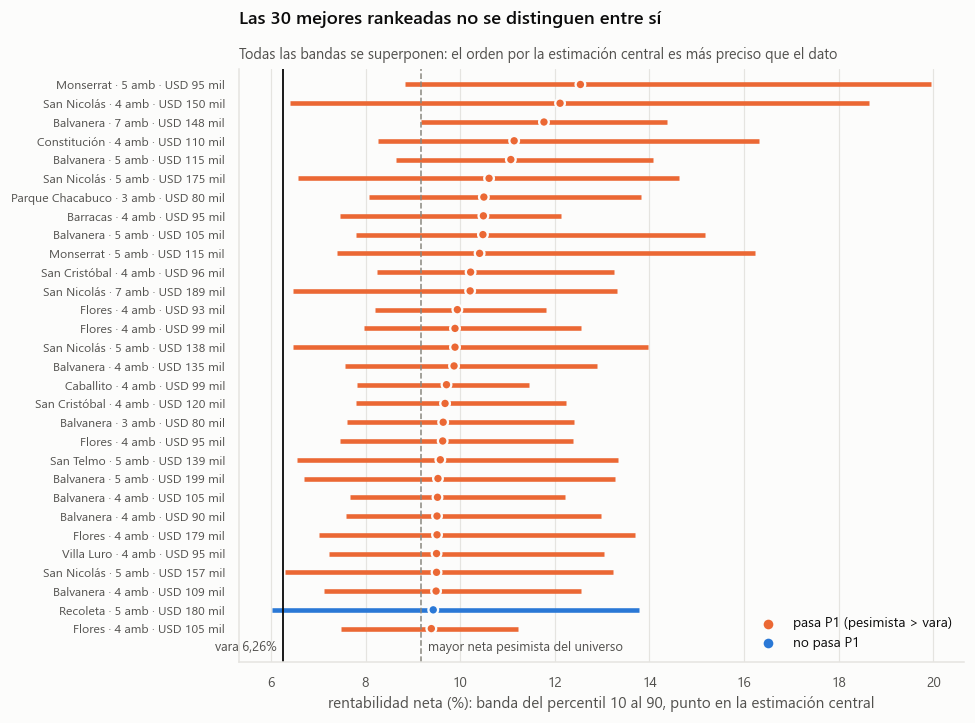

In [10]:
top = u.sort_values("rent_neta_pct", ascending=False).head(30)
corte = lo.max()
fig, ax = plt.subplots(figsize=(8.5, 7))
yy = np.arange(len(top))[::-1]
color = np.where(top["p1_comprar"], eda.SERIE_2, eda.SERIE_1)
ax.hlines(yy, top["neta_min_pct"], top["neta_max_pct"], color=color, linewidth=3)
ax.scatter(top["rent_neta_pct"], yy, s=40, color=color, edgecolor=eda.SUPERFICIE, linewidth=1.5, zorder=3)
ax.axvline(corte, color=eda.TINTA_3, linewidth=1, linestyle="--")
ax.axvline(vara, color=eda.TINTA, linewidth=1.2)
ax.annotate("mayor neta pesimista del universo", (corte, -1.2), xytext=(4, 0), textcoords="offset points",
            fontsize=8.5, color=eda.TINTA_2)
ax.annotate(f"vara {vara:.2f}%".replace(".", ","), (vara, -1.2), xytext=(-4, 0), textcoords="offset points",
            fontsize=8.5, color=eda.TINTA_2, ha="right")
etiquetas = [f"{eda.nombre_barrio(b)} · {int(a)} amb · USD {p / 1000:.0f} mil"
             for b, a, p in zip(top["barrio"], top["ambientes"], top["venta_usd"])]
ax.set_yticks(yy, etiquetas, fontsize=8)
ax.set_ylim(-1.8, len(top) - 0.2)
ax.set_xlabel("rentabilidad neta (%): banda del percentil 10 al 90, punto en la estimación central")
ax.scatter([], [], color=eda.SERIE_2, s=40, label="pasa P1 (pesimista > vara)")
ax.scatter([], [], color=eda.SERIE_1, s=40, label="no pasa P1")
ax.legend(loc="lower right")
eda.sin_grilla_y(ax)
eda.titulo(ax, "Las 30 mejores rankeadas no se distinguen entre sí",
           "Todas las bandas se superponen: el orden por la estimación central es más preciso que el dato")
eda.guardar(fig, 14, "p2_bandas_top30")
plt.show()

In [11]:
# Dentro de la frontera: lo que queda para elegir, liquidez y riesgo de estimacion.
liq = D.liquidez_por_ambientes("../data/external/estadistica_ciudad_tiempo_publicacion.csv")
print("Dias publicados por cantidad de ambientes (IDECBA, ultimo trimestre, toda la Ciudad):")
print("    " + ", ".join(f"{k}: {d:.0f}" for k, d in liq.items()))
perfil = pd.DataFrame({
    "frontera": [len(front), front["superficie_rango"].isin(["81-120", "120+"]).mean() * 100,
                 (front["neta_max_pct"] - front["neta_min_pct"]).median(), front["dias_publicacion_ambientes"].median(),
                 front["m2_relativo_celda"].median()],
    "universo": [len(u), u["superficie_rango"].isin(["81-120", "120+"]).mean() * 100,
                 (u["neta_max_pct"] - u["neta_min_pct"]).median(), u["dias_publicacion_ambientes"].median(),
                 u["m2_relativo_celda"].median()]},
    index=["propiedades", "% de mas de 80 m2", "ancho de la banda (pp)", "dias publicados (liquidez)",
           "m2 relativo a su celda"])
display(perfil)
print("Barrios de la frontera:", front["barrio"].value_counts().head(8).to_dict())

Dias publicados por cantidad de ambientes (IDECBA, ultimo trimestre, toda la Ciudad):
    Total: 298, 1 ambiente: 297, 2 ambientes: 303, 3 ambientes: 296, 4 ambientes: 286, 5 ambientes y más: 349


,frontera,universo
propiedades,397.00,"3,766.00"
% de mas de 80 m2,54.66,19.84
ancho de la banda (pp),4.73,2.68
dias publicados (liquidez),295.50,295.50
m2 relativo a su celda,0.86,1.00


Barrios de la frontera: {'balvanera': 64, 'san nicolas': 45, 'monserrat': 34, 'almagro': 33, 'san telmo': 28, 'flores': 24, 'floresta': 22, 'san cristobal': 21}


**Lectura.**

- **La banda casi nunca permite elegir.** En más del 90% de los pares las bandas se
  superponen, y comparando unidades del mismo tamaño o del mismo barrio la proporción
  distinguible es todavía menor. **Un ranking propiedad por propiedad sería más preciso
  que el dato que lo sostiene.**
- **La frontera es una lista, no una propiedad** (su tamaño se imprime arriba). Ninguna
  otra la supera con claridad, y entre ellas no se distinguen. En ella pesan las
  unidades de más de 80 m², las de barrios de m² barato y las que cuestan menos que su
  celda.
- **La frontera depende de una sola propiedad:** la de mayor neta pesimista fija el
  piso que hay que alcanzar. Si esa propiedad no corresponde (una oficina, un precio que
  no es el total), la frontera cambia entera. Es otra razón para leer a mano los
  primeros puestos.
- **Parte de la frontera se explica por la incertidumbre.** La banda mediana de la
  frontera es mucho más ancha que la del universo. Una banda ancha llega más arriba por
  el lado optimista, así que una propiedad puede quedar en la frontera porque el modelo
  sabe poco de ella, no porque rinda más.
- **El desempate por liquidez casi no discrimina.** El tiempo de publicación de IDECBA
  solo existe por cantidad de ambientes y para toda la Ciudad, y varía poco entre 1 y 4
  ambientes. **El desempate que sí informa es el riesgo de estimación:** entre dos
  propiedades de la frontera, la de banda más angosta tiene una rentabilidad que se
  conoce mejor.

## 4. P3 — ¿Tradicional o temporal?

**Método.** Para cada celda barrio × dormitorios con datos de los dos lados, la
**ocupación de equilibrio**: con cuánta ocupación el temporal empata al tradicional, neta
contra neta (`temporal.py`). El temporal se recomienda solo si la ocupación que se puede
sostener supera ese umbral. Como la ocupación no se observa, se evalúa en todo el rango.

In [12]:
eq = D.ocupacion_equilibrio(temporal, S.VACANCIA_PCT)
eq_auto = D.ocupacion_equilibrio(temporal, S.VACANCIA_PCT, autogestion=True)
print(f"Celdas: {len(temporal)}. Ocupacion de equilibrio mediana: {eq.median():.1f}% con gestion tercerizada, "
      f"{eq_auto.median():.1f}% autogestionado")
print(f"Ocupacion estimada por Inside Airbnb (mediana de las celdas): {temporal['ocupacion_mediana_pct'].median():.1f}%; "
      f"referencia de prensa: {S.OCUPACION_REF_PCT:.0f}%")
base = p3[p3["vacancia_tradicional_pct"] == S.VACANCIA_PCT]
tabla = base.pivot(index="ocupacion_sostenible_pct", columns="gestion", values="gana_temporal")
tabla.rename_axis("ocupacion sostenible (%)").T

Celdas: 47. Ocupacion de equilibrio mediana: 65.5% con gestion tercerizada, 51.7% autogestionado
Ocupacion estimada por Inside Airbnb (mediana de las celdas): 18.6%; referencia de prensa: 53%


ocupacion sostenible (%),20.00,30.00,40.00,50.00,53.00,60.00,70.00,80.00
gestion,,,,,,,,
autogestionado,0,0,0,20,28,45,47,47
tercerizada,0,0,0,0,2,11,35,46


### Gráfico 15 — ¿Con cuánta ocupación conviene el temporal?

Cantidad de celdas barrio × dormitorios (de 47) en las que el temporal le gana al
tradicional, según la ocupación que el inversor pueda sostener, con gestión tercerizada
y autogestionado.

guardado: ../graficos\15_p3_ocupacion.png


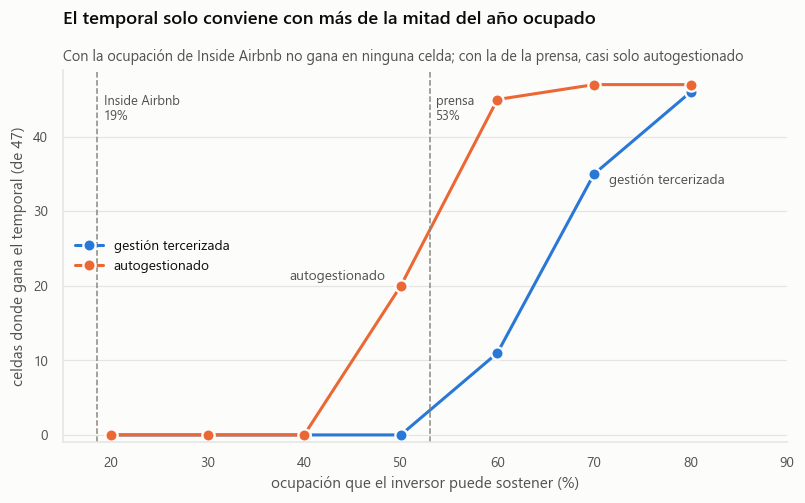

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
grilla = base[base["ocupacion_sostenible_pct"].isin(S.SENSIBILIDAD_OCUPACION)]
# Rotulo directo de cada curva sobre su tramo empinado, donde no se cruzan.
rotulos = {"tercerizada": (70, (10, -4), "left", "gestión tercerizada"),
           "autogestionado": (50, (-10, 6), "right", "autogestionado")}
for gestion, color in [("tercerizada", eda.SERIE_1), ("autogestionado", eda.SERIE_2)]:
    g = grilla[grilla["gestion"] == gestion].sort_values("ocupacion_sostenible_pct")
    ax.plot(g["ocupacion_sostenible_pct"], g["gana_temporal"], color=color, marker="o",
            markeredgecolor=eda.SUPERFICIE, markeredgewidth=1.5, label=rotulos[gestion][3])
    x_r, off, ha, texto = rotulos[gestion]
    ax.annotate(texto, (x_r, g.set_index("ocupacion_sostenible_pct").loc[x_r, "gana_temporal"]), xytext=off,
                textcoords="offset points", fontsize=9, color=eda.TINTA_2, ha=ha, va="center")
oc_airbnb = temporal["ocupacion_mediana_pct"].median()
for x_, texto in [(oc_airbnb, f"Inside Airbnb\n{oc_airbnb:.0f}%"), (S.OCUPACION_REF_PCT, f"prensa\n{S.OCUPACION_REF_PCT:.0f}%")]:
    ax.axvline(x_, color=eda.TINTA_3, linewidth=1, linestyle="--")
    ax.annotate(texto, (x_, len(temporal) * 0.97), xytext=(4, 0), textcoords="offset points", fontsize=8.5,
                color=eda.TINTA_2, va="top")
ax.set_xlim(15, 90)
ax.set_ylim(-1, len(temporal) + 2)
ax.set_xlabel("ocupación que el inversor puede sostener (%)")
ax.set_ylabel(f"celdas donde gana el temporal (de {len(temporal)})")
ax.legend(loc="center left")
eda.titulo(ax, "El temporal solo conviene con más de la mitad del año ocupado",
           "Con la ocupación de Inside Airbnb no gana en ninguna celda; con la de la prensa, casi solo autogestionado")
eda.guardar(fig, 15, "p3_ocupacion")
plt.show()

**Lectura. P3 se responde tradicional, con una condición.**

- **Con gestión tercerizada**, el temporal necesita una ocupación cercana al 65% para
  empatar. Con la ocupación que estima Inside Airbnb no gana en ninguna celda, y con el
  53% que informa la prensa gana en 2 de 47.
- **Autogestionado**, el umbral baja a alrededor de 52%, y con el 53% de la prensa gana en
  más de la mitad de las celdas.

El temporal conviene solo para un inversor que lo opere por su cuenta y que tenga
evidencia de poder sostener más de la mitad del año ocupado. Las dos ocupaciones de
referencia son estimaciones, no datos observados, y autogestionar es un trabajo, no un
ahorro (`supuestos.py`, sección 4c).

## 5. Sensibilidad: ¿cuánto depende la recomendación de los supuestos?

Un parámetro por vez, con los demás en el caso base, y dos escenarios extremos que mueven
todo a favor y todo en contra de comprar. Además de la vacancia, los gastos, el ABL, los
costos de entrada, la banda de retorno y el margen por liquidez, se prueban la
**refacción** (mínima o integral), la **suba del alquiler al refaccionar** (sin suba, el
efecto de `reciclado` y el efecto completo del modelo) y otro **horizonte** (3 años, con
la ON de 3 años como vara). Los costos de entrada y la refacción son parámetros
separados: en el escenario sin costos de entrada, la obra se sigue pagando. Para cada
escenario se compara el conjunto recomendado con el del caso base mediante el índice de
Jaccard: 1 significa las mismas propiedades, 0, ninguna en común.

In [14]:
cols = ["parametro", "vacancia", "gastos_sin_abl", "abl", "entrada", "refaccion", "suba", "horizonte", "umbral",
        "margen", "n_p1", "n_p1_con_entrada", "jaccard_p1_vs_base", "n_frontera_p2", "jaccard_frontera_vs_base",
        "pares_distinguibles_pct"]
display(sens[cols])
b = sens.iloc[0]
fila = lambda p, **k: sens[(sens["parametro"] == p) & np.logical_and.reduce([sens[c] == x for c, x in k.items()])].iloc[0]
print(f"Base: {b['n_p1']} pasan P1, {b['n_p1_con_entrada']} con costos de entrada")
print(f"Sin costos de entrada (la obra se paga): {fila('costos de entrada', entrada='sin')['n_p1_con_entrada']} con la TIR")
for s_ in S.SENSIBILIDAD_SUBA_REFACCION:
    print(f"Suba por refaccion '{s_}': {fila('suba por refaccion', suba=s_)['n_p1_con_entrada']} con costos de entrada")
h = sens[sens["parametro"] == "horizonte"].iloc[0]
print(f"Horizonte {int(h['horizonte'])} anios (vara {h['umbral']:.2f}%): {h['n_p1']} pasan P1, "
      f"{h['n_p1_con_entrada']} con costos de entrada")
print(f"Vara en el p25 de la banda: {fila('banda de retorno', umbral=S.RETORNO_MIN_PISO_PCT)['n_p1']}; "
      f"en el p75: {fila('banda de retorno', umbral=S.RETORNO_MIN_TECHO_PCT)['n_p1']}")

,parametro,vacancia,gastos_sin_abl,abl,entrada,refaccion,suba,horizonte,umbral,margen,n_p1,n_p1_con_entrada,jaccard_p1_vs_base,n_frontera_p2,jaccard_frontera_vs_base,pares_distinguibles_pct
0,base,5.88,10.24,segmentado,base,base,reciclado,5,6.26,0.00,93,12,1.00,396,1.00,7.24
1,vacancia,4.00,10.24,segmentado,base,base,reciclado,5,6.26,0.00,111,15,0.84,396,1.00,7.24
2,vacancia,6.00,10.24,segmentado,base,base,reciclado,5,6.26,0.00,93,12,1.00,396,1.00,7.24
3,vacancia,8.00,10.24,segmentado,base,base,reciclado,5,6.26,0.00,81,10,0.87,396,1.00,7.24
4,vacancia,10.00,10.24,segmentado,base,base,reciclado,5,6.26,0.00,61,7,0.66,396,1.00,7.24
5,vacancia,12.00,10.24,segmentado,base,base,reciclado,5,6.26,0.00,48,5,0.52,396,1.00,7.24
6,gastos sin ABL,5.88,8.24,segmentado,base,base,reciclado,5,6.26,0.00,116,16,0.80,396,1.00,7.25
7,gastos sin ABL,5.88,10.24,segmentado,base,base,reciclado,5,6.26,0.00,93,12,1.00,396,1.00,7.24
8,gastos sin ABL,5.88,12.24,segmentado,base,base,reciclado,5,6.26,0.00,78,10,0.84,396,1.00,7.22
9,ABL,5.88,10.24,plano,base,base,reciclado,5,6.26,0.00,106,12,0.88,368,0.92,8.10


Base: 93 pasan P1, 12 con costos de entrada
Sin costos de entrada (la obra se paga): 83 con la TIR
Suba por refaccion 'sin': 12 con costos de entrada
Suba por refaccion 'reciclado': 12 con costos de entrada
Suba por refaccion 'modelo': 12 con costos de entrada
Horizonte 3 anios (vara 5.23%): 474 pasan P1, 17 con costos de entrada
Vara en el p25 de la banda: 115; en el p75: 62


In [15]:
q = p3[p3["ocupacion_sostenible_pct"] == S.OCUPACION_REF_PCT].pivot(index="vacancia_tradicional_pct",
                                                                     columns="gestion", values="gana_temporal")
print(f"P3: celdas donde gana el temporal con {S.OCUPACION_REF_PCT:.0f}% de ocupacion, segun la vacancia del tradicional")
q

P3: celdas donde gana el temporal con 53% de ocupacion, segun la vacancia del tradicional


gestion,autogestionado,tercerizada
vacancia_tradicional_pct,,
4.00,27,1
5.88,28,2
6.00,28,2
8.00,30,2
10.00,34,3
12.00,36,3


**Lectura.**

- **P1 es robusto en su conclusión, no en su lista.** En todos los escenarios con el
  horizonte de 5 años pasa una parte chica del universo, incluido el extremo favorable.
  Qué propiedades pasan, en cambio, se mueve bastante: un margen por liquidez de 1 punto
  o la vara en el p75 de la banda achican mucho la lista.
- **El supuesto de la refacción no cambia la recomendación.** Con costos de entrada,
  pasan las mismas sin suba, con el caso base y con el efecto completo del modelo: el
  coeficiente de `a_reciclar`, que se apoya en muy pocos alquileres, no decide nada. En
  el escenario sin costos de entrada las unidades a reciclar siguen pagando la obra.
- **El horizonte importa en las dos puntas.** A 3 años la vara baja (la ON de 3 años
  rinde menos), así que pasan muchas más por la neta; pero con costos de entrada, que se
  reparten en menos años, el resultado casi no cambia.
- **La frontera de P2 casi no se mueve.** La vacancia y los gastos sin ABL escalan todas
  las netas por igual y no cambian qué banda domina a cuál; lo que más la mueve es la
  definición del ABL. Los pares distinguibles quedan en un rango angosto.
- **P3 no cambia de signo** con ninguna vacancia razonable del tradicional.


## 6. La salida: ¿cuántas son aptas para crédito?

La TIR supone revender al mismo precio, y quién puede comprar cuando el inversor venda
importa. Una unidad **apta para crédito hipotecario** se puede vender a quien compra con
hipoteca, además de a quien paga al contado. La variable `apto_credito` marca el aviso
que lo dice (con veto por negación: "no apto crédito" no cuenta); no decirlo no es no
serlo, así que la proporción es un piso. Se compara además el m² de las aptas con sus
comparables de la misma celda barrio × tramo (Van Elteren, como H3). El cálculo está en
`src/credito_y_verdes.py`.


In [16]:

import credito_y_verdes as CV
from fuentes_externas import Reporte

rep = Reporte()
filas_credito = CV.credito(df, rep)
print("\n".join(rep.lineas))



1. AVISOS APTOS PARA CREDITO HIPOTECARIO
Proporcion de avisos que declaran ser aptos para credito (un piso: no decirlo no es no serlo)
    ventas                              2,590 de 10,749   24.1%
    ventas en el presupuesto            1,540 de  6,062   25.4%
    universo de la decision             1,054 de  3,766   28.0%
    P1: pasan sin costos de entrada        32 de     93   34.4%
    P1: pasan con costos de entrada         4 de     12   33.3%

Por tipo de propiedad (ventas):
    casa            17.3%  (683 avisos)
    departamento    24.9%  (8,658 avisos)
    ph              22.6%  (1,408 avisos)



Precio del m2, aptas contra no aptas en la misma celda barrio x tramo (149 celdas):
    diferencia mediana ponderada: -5.2%   Van Elteren p bilateral = 2.4e-12

1. AVISOS APTOS PARA CREDITO HIPOTECARIO
Proporcion de avisos que declaran ser aptos para credito (un piso: no decirlo no es no serlo)
    ventas                              2,590 de 10,749   24.1%
    ventas en el presupuesto            1,540 de  6,062   25.4%
    universo de la decision             1,054 de  3,766   28.0%
    P1: pasan sin costos de entrada        32 de     93   34.4%
    P1: pasan con costos de entrada         4 de     12   33.3%

Por tipo de propiedad (ventas):
    casa            17.3%  (683 avisos)
    departamento    24.9%  (8,658 avisos)
    ph              22.6%  (1,408 avisos)

Precio del m2, aptas contra no aptas en la misma celda barrio x tramo (149 celdas):
    diferencia mediana ponderada: -5.2%   Van Elteren p bilateral = 2.4e-12



**Lectura.** Alrededor de un cuarto de la oferta se declara apta para crédito, y la
proporción es algo mayor en el universo de la decisión y entre las que pasan P1. Contra
sus comparables de la misma celda, las aptas no cotizan más caras sino algo más baratas:
es una asociación, que puede venir de lo que la celda no controla (antigüedad, estado,
quién publica). **Para el inversor:** entre dos candidatas parecidas, preferir la apta
para crédito no cuesta más y amplía el mercado de la reventa, en una Ciudad donde una
parte chica de las compraventas se hace con hipoteca.


## Resumen: qué recomienda la función de decisión

In [17]:

pas, pe = int(u["p1_comprar"].sum()), int(u["p1_comprar_con_entrada"].sum())
fr = int(u["p2_no_dominada"].sum())
pares = D.pares_distinguibles(u["neta_min_pct"], u["neta_max_pct"]) * 100
coma = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
display(Markdown(f"""
| Decisión | Recomendación | Evaluación |
|---|---|---|
| **P1** — ¿comprar? | **No, para la propiedad típica.** {pas} de {coma(len(u), 0)} propiedades superan la vara ({coma(vara, 2)}%, ON a {S.HORIZONTE_ANIOS} años) en el escenario pesimista, y {pe} con costos de entrada | Las que pasan son baratas para su celda y se leyeron a mano: {int(u.loc[u['p1_comprar'], 'alerta_revision'].notna().sum())} llevan una alerta. Robusto en la conclusión, inestable en la lista |
| **P2** — ¿cuál? | **Una lista corta, no una propiedad.** {coma(fr, 0)} propiedades no dominadas, que no se distinguen entre sí | Solo el {coma(pares)}% de los pares se distingue con la banda. Desempate por ancho de banda (riesgo de estimación); la liquidez disponible no discrimina |
| **P3** — ¿tradicional o temporal? | **Tradicional**, salvo un inversor que autogestione y pueda sostener más de alrededor de {coma(eq_auto.median(), 0)}% de ocupación | Con gestión tercerizada el equilibrio mediano es {coma(eq.median())}%; la ocupación observable no lo alcanza en ninguna celda |
"""))



| Decisión | Recomendación | Evaluación |
|---|---|---|
| **P1** — ¿comprar? | **No, para la propiedad típica.** 93 de 3.766 propiedades superan la vara (6,26%, ON a 5 años) en el escenario pesimista, y 12 con costos de entrada | Las que pasan son baratas para su celda y se leyeron a mano: 15 llevan una alerta. Robusto en la conclusión, inestable en la lista |
| **P2** — ¿cuál? | **Una lista corta, no una propiedad.** 397 propiedades no dominadas, que no se distinguen entre sí | Solo el 7,2% de los pares se distingue con la banda. Desempate por ancho de banda (riesgo de estimación); la liquidez disponible no discrimina |
| **P3** — ¿tradicional o temporal? | **Tradicional**, salvo un inversor que autogestione y pueda sostener más de alrededor de 52% de ocupación | Con gestión tercerizada el equilibrio mediano es 65,5%; la ocupación observable no lo alcanza en ninguna celda |



**Lo que la función no hace.**
- No incluye apreciación ni costos de salida.
- No incluye riesgo legal, que es una limitación declarada.
- No incluye casas ni PH, que están fuera del soporte del modelo.
- La liquidez es la de toda la Ciudad por cantidad de ambientes, no la de cada propiedad.
- Todos los precios son de publicación, de una sola inmobiliaria.
